# Métriques du modèle de fréquence (probabilité de sinistre)

**Courbe ROC**
*Image* : on baisse progressivement le seuil d'alerte, de « personne n'est signalé » à « tout le monde est signalé ». À chaque seuil, on note la part des vrais sinistrés détectés (en vertical) et la part des non-sinistrés signalés à tort (en horizontal). La courbe trace ce compromis. Plus elle monte vite vers le coin en haut à gauche, mieux le modèle détecte sans fausses alertes.

**ROC AUC (aire sous la courbe ROC)**
*Image* : on tire au sort **un assuré sinistré et un assuré non sinistré**. L'AUC est la probabilité que le modèle donne le risque le plus élevé au sinistré.
- 0,5 = pile ou face ; 1 = classement parfait.
- **Votre modèle : 0,664**, soit le bon ordre dans 2 paires sur 3. Pour la fréquence auto, c'est modeste mais réaliste.

**PR AUC (aire sous la courbe précision-rappel)**
*Image* : quand le modèle signale des assurés « à risque », quelle part est réellement sinistrée, en moyenne sur tous les seuils ?
- Le hasard vaut le taux de sinistres : **0,058**.
- **Votre modèle : 0,098**, soit **1,7 fois mieux** qu'un tirage au hasard.
- Elle est plus exigeante que l'AUC quand l'événement est rare, car elle se concentre sur les 5,8 % de sinistrés.

**Brier score**
*Image* : la note d'un météorologue. S'il annonce 10 % de pluie et qu'il pleut, il est pénalisé de (1 − 0,10)² ; s'il ne pleut pas, de (0 − 0,10)². Le Brier est la moyenne de ces pénalités.
- 0 = parfait. Plus il est bas, plus les probabilités sont justes.
- **Votre modèle : 0,0539**, contre **0,0549** pour le naïf (−2 %). Le gain est faible, ce qui est normal : un accident individuel reste largement imprévisible.

**Log loss** (variante du Brier)
Même idée, mais elle punit très fortement une **certitude erronée** : annoncer 1 % de risque à quelqu'un qui a un sinistre coûte très cher.

**Probabilité moyenne prédite (calibration globale)**
*Image* : le modèle annonce-t-il, en moyenne, le bon nombre de sinistres ?
- **5,85 % prédits contre 5,83 % observés** : le modèle ne surestime ni ne sous-estime le risque du portefeuille.

**Lift par décile**
*Image* : on range les assurés du moins risqué au plus risqué, en 10 groupes égaux. Le lift indique combien de fois un groupe est plus sinistré que la moyenne.
- 1 = comme la moyenne ; 2 = deux fois plus de sinistres.
- **Votre modèle** : du décile le plus sûr au plus risqué, le taux de sinistres va de **1,1 % à 11,2 %**, avec un lift d'environ **1,7** sur le dernier décile. C'est la mesure la plus parlante en tarification.

**Gain cumulé**
*Image* : si l'assureur ne pouvait surveiller qu'une partie de ses clients, quelle part des sinistres capterait-il ?
- **Les 30 % les plus risqués concentrent 43,5 % des sinistres**, contre 30 % au hasard.

**Precision, recall, F1** (seulement si une décision oui/non est prise)
- *Precision* : parmi les assurés signalés, combien ont vraiment un sinistre ?
- *Recall* : parmi les vrais sinistrés, combien ont été signalés ?
- *F1* : un compromis entre les deux.
- Elles dépendent d'un seuil arbitraire, donc elles ne sont pas adaptées à l'objectif de produire une probabilité.

## Métriques du modèle de montant

**RMSE**
*Image* : l'erreur « typique » d'une prédiction, en euros, qui grossit fortement les grosses erreurs.
- **XGBoost : 1 444 €**, contre **1 456 €** pour le naïf (−0,9 %).
- Le coût d'un sinistre individuel est quasi imprévisible avec les informations du contrat.

**MAE**
*Image* : l'erreur moyenne en euros, sans grossir les grosses erreurs.
- **XGBoost : 928 €** contre **954 €** pour le naïf.
- L'écart avec la RMSE montre que quelques sinistres très coûteux concentrent l'erreur.

**R²**
*Image* : la part des variations du montant que le modèle explique.
- 0 = rien ; 1 = tout.
- **Environ 1,5 %** : les 98 % restants dépendent des circonstances de l'accident, absentes des données.

**Écart-type de la RMSE (validation croisée)**
*Image* : la variation du score selon les sinistres tirés dans le jeu de test, c'est-à-dire la marge d'incertitude.
- **Environ 150 €** : tout écart entre modèles plus petit que cela est du hasard. C'est pourquoi tous les modèles de montant sont jugés équivalents.

**Ratio total prédit / observé**
*Image* : l'assureur encaisse-t-il assez pour payer l'ensemble des sinistres ?
- **1,000** : la charge totale est estimée exactement. C'est le critère qui compte le plus pour un assureur.

## Le message clé pour la présentation
Aucun modèle ne prédit le sinistre ou le coût d'un assuré précis. Mais le projet **classe correctement les assurés par niveau de risque** (lift, AUC) et **estime juste la charge totale** (calibration, ratio de 1,000). Ce sont exactement les deux propriétés dont un assureur a besoin pour tarifer.

In [8]:
import pandas as pd 
import numpy as np
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display


from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer


from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

In [9]:
from pathlib import Path
RACINE = Path.cwd().parent if Path.cwd().name == "developement" else Path.cwd()
DATA_PATH = (RACINE / "data" / "train.csv") if (RACINE / "data" / "train.csv").exists() else (RACINE / "train.csv")
initial_train_set = pd.read_csv(DATA_PATH, sep=",")


In [10]:
# Cible de fréquence
initial_train_set["sinistre"] = (initial_train_set["nombre_sinistres"] > 0).astype(int)
print(initial_train_set["nombre_sinistres"].value_counts().sort_index())

# Jeu complet : Random Forest / gradient boosting
num_rf = ["bonus", "anciennete_vehicule", "din_vehicule", "anciennete_permis1",
          "age_conducteur1", "cylindre_vehicule", "age_conducteur2", "anciennete_permis2",
          "prix_vehicule", "poids_vehicule", "vitesse_vehicule",
          "debut_vente_vehicule", "fin_vente_vehicule"]
cat_rf = ["type_contrat", "type_vehicule", "essence_vehicule", "conducteur2"]

# # Jeu réduit : régression logistique (un représentant par groupe redondant)
# num_glm = ["bonus", "anciennete_vehicule", "din_vehicule", "anciennete_permis1"]
# cat_glm = ["type_contrat", "type_vehicule", "essence_vehicule", "conducteur2"]

X = initial_train_set[num_rf + cat_rf]
y = initial_train_set["sinistre"]

nombre_sinistres
0    47083
1     2917
Name: count, dtype: int64


In [11]:
# 1. On isole le test 
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.10, stratify=y, random_state=42)

# 2. On coupe le reste en train 
X_train, X_dev, y_train, y_dev = train_test_split(
    X_temp, y_temp, test_size=0.20, stratify=y_temp, random_state=42)

for nom, Xs, ys in [("Train", X_train, y_train), ("Dev", X_dev, y_dev), ("Test", X_test, y_test)]:
    print(f"{nom:5s} : {Xs.shape[0]:6d} lignes ({Xs.shape[0] / len(X):.0%}) | taux sinistre {ys.mean():.2%}")

Train :  36000 lignes (72%) | taux sinistre 5.83%
Dev   :   9000 lignes (18%) | taux sinistre 5.83%
Test  :   5000 lignes (10%) | taux sinistre 5.84%


In [12]:
def manquants_structurels(X):
    """Sans second conducteur : âge et permis à 0, pas une médiane."""
    X = X.copy()
    sans_c2 = X["conducteur2"] == "No"
    X.loc[sans_c2, ["age_conducteur2", "anciennete_permis2"]] = 0
    return X

colonnes = ColumnTransformer([
    ("num", SimpleImputer(strategy="median", add_indicator=True), num_rf), 
    ("cat", Pipeline([
        ("imputation", SimpleImputer(strategy="constant", fill_value="Inconnu")),
        ("encodage", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                   min_frequency=30, drop="if_binary",
                                   sparse_output=False)),
    ]), cat_rf),
])

preprocesseur = Pipeline([
    ("structurels", FunctionTransformer(manquants_structurels, feature_names_out="one-to-one")),
    ("colonnes", colonnes),
])

- Tranformation de données - Encodage - Gestion des inférences à valeurs vides

In [13]:
Xtr = preprocesseur.fit_transform(X_train)   # fit sur le train uniquement
Xdv = preprocesseur.transform(X_dev)
Xte = preprocesseur.transform(X_test)

print(f"Train {Xtr.shape} | Dev {Xdv.shape} | Test {Xte.shape}")
print(f"NaN : {np.isnan(Xtr).sum()}, {np.isnan(Xdv).sum()}, {np.isnan(Xte).sum()}")
print(list(preprocesseur.get_feature_names_out()))

Train (36000, 23) | Dev (9000, 23) | Test (5000, 23)
NaN : 0, 0, 0
['num__bonus', 'num__anciennete_vehicule', 'num__din_vehicule', 'num__anciennete_permis1', 'num__age_conducteur1', 'num__cylindre_vehicule', 'num__age_conducteur2', 'num__anciennete_permis2', 'num__prix_vehicule', 'num__poids_vehicule', 'num__vitesse_vehicule', 'num__debut_vente_vehicule', 'num__fin_vente_vehicule', 'num__missingindicator_anciennete_vehicule', 'cat__type_contrat_Maxi', 'cat__type_contrat_Median1', 'cat__type_contrat_Median2', 'cat__type_contrat_Mini', 'cat__type_vehicule_Tourism', 'cat__essence_vehicule_Diesel', 'cat__essence_vehicule_Gasoline', 'cat__essence_vehicule_Hybrid', 'cat__conducteur2_Yes']


# Entrainement 

In [14]:
def evaluer(modele, X, y, nom=""):
    p = modele.predict_proba(X)[:, 1]
    return {"jeu": nom,
            "ROC_AUC": roc_auc_score(y, p),
            "PR_AUC": average_precision_score(y, p),
            "Brier": brier_score_loss(y, p),
            "proba_moy": p.mean()}

# Référence : prédit le taux moyen pour tout le monde
naif = Pipeline([("prep", preprocesseur), ("modele", DummyClassifier(strategy="prior"))])
naif.fit(X_train, y_train)

# Random Forest
rf = Pipeline([
    ("prep", preprocesseur),
    ("modele", RandomForestClassifier(n_estimators=300, min_samples_leaf=100,
                                      max_features="sqrt", n_jobs=-1, random_state=42)),
])
rf.fit(X_train, y_train)

res = pd.DataFrame([
    evaluer(naif, X_dev, y_dev, "Naïf - dev"),
    evaluer(rf, X_train, y_train, "RF - train"),
    evaluer(rf, X_dev, y_dev, "RF - dev"),
]).round(4)
display(res)

,jeu,ROC_AUC,PR_AUC,Brier,proba_moy
0,Naïf - dev,0.5000,0.0583,0.0549,0.0583
1,RF - train,0.7524,0.1611,0.0528,0.0584
2,RF - dev,0.6656,0.0994,0.0539,0.0585


- Interpretation 

Modèle de fréquence — Random Forest (leaf=100, sqrt) contre modèle naïf

Sur le jeu de dev, le Random Forest atteint un ROC AUC de 0,666 contre 0,5 pour le modèle naïf : il classe les assurés par niveau de risque nettement mieux que le hasard, avec une performance modeste mais réaliste pour la fréquence de sinistres auto. Son PR AUC de 0,099, contre 0,058 pour le naïf, montre qu’il repère les assurés sinistrés environ 1,7 fois mieux qu’un tirage au hasard. Le Brier passe de 0,0549 à 0,0539 (−2 %) : la qualité des probabilités s’améliore légèrement, ce qui est attendu pour un événement rare et largement aléatoire. La probabilité moyenne prédite (5,85 %) est égale au taux réel (5,83 %) : le modèle est bien calibré au niveau du portefeuille. L’écart d’AUC entre train (0,752) et dev (0,666) signale un surapprentissage modéré, ce qui justifie la grille d’hyperparamètres et le choix final d’un min_samples_leaf plus élevé.

In [ ]:
resultats = []
base = evaluer(naif, X_dev, y_dev)
for leaf in [20, 50, 100, 200, 400]:
    for mf in ["sqrt", 0.5]:
        rf.set_params(modele__min_samples_leaf=leaf, modele__max_features=mf)
        rf.fit(X_train, y_train)
        r_tr = evaluer(rf, X_train, y_train)
        r_dv = evaluer(rf, X_dev, y_dev)
        resultats.append({"min_leaf": leaf, "max_features": mf,
                          "AUC_train": r_tr["ROC_AUC"], "AUC_dev": r_dv["ROC_AUC"],
                          "ecart": r_tr["ROC_AUC"] - r_dv["ROC_AUC"],
                          "PR_AUC_dev": r_dv["PR_AUC"], "Brier_dev": r_dv["Brier"]})



In [28]:
grille = pd.DataFrame(resultats).sort_values("AUC_dev", ascending=False).round(4)
grille = grille.rename(columns={"AUC_dev": "ROC_AUC", "PR_AUC_dev": "PR_AUC",
                                "Brier_dev": "Brier", "ecart": "ecart_AUC"})
grille["config"] = "leaf=" + grille["min_leaf"].astype(str) + " | mf=" + grille["max_features"].astype(str)
display(grille)

,min_leaf,max_features,AUC_train,ROC_AUC,ecart_AUC,PR_AUC,Brier,config
2,50,sqrt,0.8183,0.6665,0.1517,0.1008,0.0539,leaf=50 | mf=sqrt
4,100,sqrt,0.7524,0.6656,0.0868,0.0994,0.0539,leaf=100 | mf=sqrt
6,200,sqrt,0.7066,0.6643,0.0423,0.0977,0.0539,leaf=200 | mf=sqrt
8,400,sqrt,0.6784,0.6626,0.0158,0.0981,0.0540,leaf=400 | mf=sqrt
9,400,0.5,0.6897,0.6621,0.0276,0.0968,0.0540,leaf=400 | mf=0.5
5,100,0.5,0.7794,0.6621,0.1173,0.1003,0.0539,leaf=100 | mf=0.5
7,200,0.5,0.7243,0.6616,0.0626,0.0974,0.0540,leaf=200 | mf=0.5
0,20,sqrt,0.9169,0.6612,0.2557,0.1013,0.0540,leaf=20 | mf=sqrt
3,50,0.5,0.8507,0.6584,0.1922,0.1006,0.0540,leaf=50 | mf=0.5
1,20,0.5,0.9416,0.6516,0.2900,0.1020,0.0541,leaf=20 | mf=0.5


- Interpretation 

Grille d’hyperparamètres du Random Forest (fréquence, jeu de dev)

Les 10 combinaisons testées obtiennent un ROC AUC très proche, entre 0,652 et 0,667, et un Brier quasi identique (0,0539 à 0,0541) : les hyperparamètres modifient peu la performance sur le dev. Ils changent en revanche fortement le surapprentissage : l’écart entre train et dev passe de 0,29 (leaf=20) à 0,016 (leaf=400), car des feuilles plus grandes empêchent le modèle de mémoriser les données. La meilleure configuration nominale (leaf=50, sqrt, AUC 0,6665) surapprend nettement (écart 0,15), alors que leaf=200 avec sqrt perd seulement 0,002 d’AUC pour un écart réduit à 0,04. max_features="sqrt" fait systématiquement au moins aussi bien que 0,5. La configuration retenue est donc leaf=200, sqrt : même performance de fait, meilleure capacité à généraliser.

In [32]:
# grille = grille.rename(columns={
#     "AUC_dev": "ROC_AUC",
#     "PR_AUC_dev": "PR_AUC",
#     "Brier_dev": "Brier",
#     "ecart": "ecart_AUC",
# })
# if "config" not in grille.columns:
#     grille["config"] = "leaf=" + grille["min_leaf"].astype(str) + " | mf=" + grille["max_features"].astype(str)

# print(grille.columns.tolist())

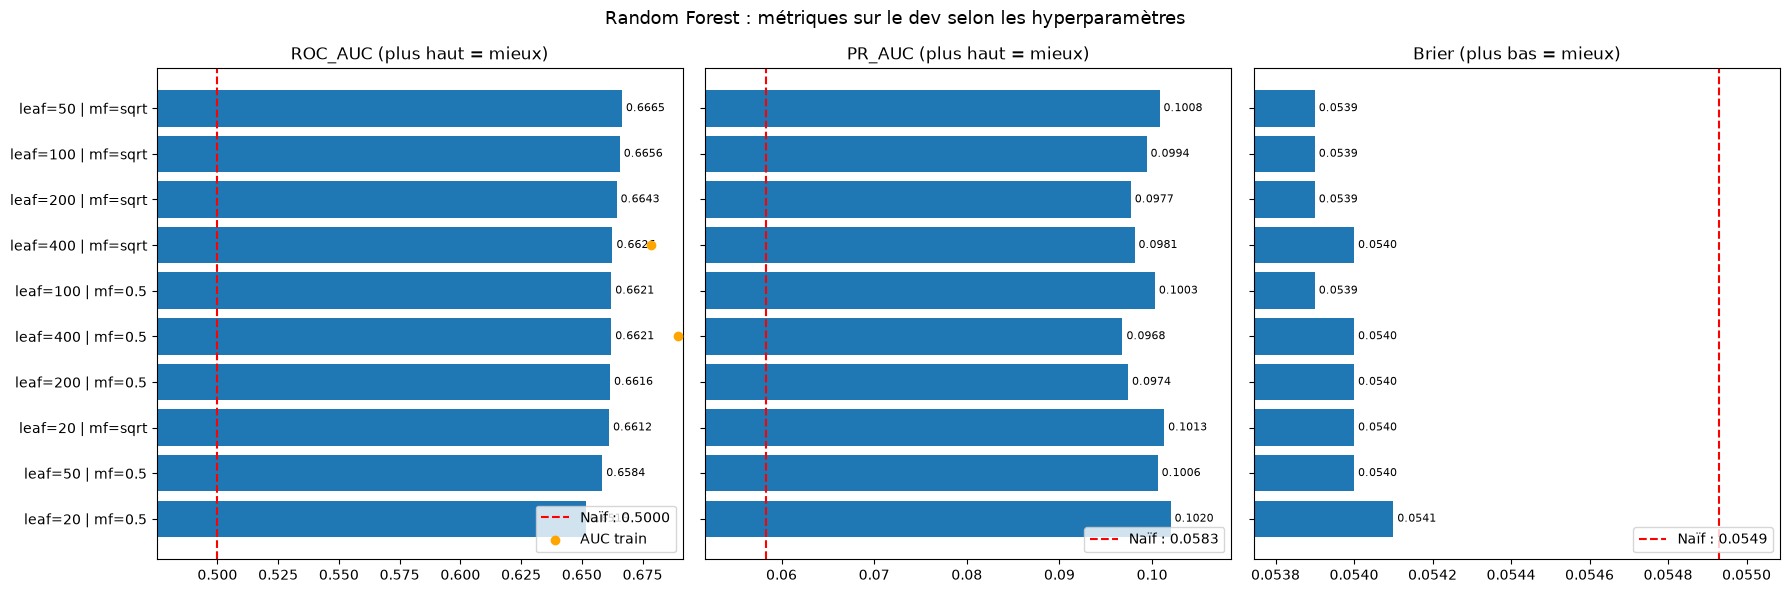

In [33]:
metriques = [("ROC_AUC", "plus haut = mieux"),
             ("PR_AUC", "plus haut = mieux"),
             ("Brier", "plus bas = mieux")]

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
ordre = grille.sort_values("ROC_AUC")   # meilleure config en haut

for ax, (m, sens) in zip(axes, metriques):
    ax.barh(ordre["config"], ordre[m], color="tab:blue")
    ax.axvline(base[m], color="red", ls="--", lw=1.5, label=f"Naïf : {base[m]:.4f}")

    # zoom sur la zone utile, sinon les écarts sont invisibles
    vals = list(ordre[m]) + [base[m]]
    marge = (max(vals) - min(vals)) * 0.15
    ax.set_xlim(min(vals) - marge, max(vals) + marge)

    for y_pos, v in enumerate(ordre[m]):
        ax.text(v, y_pos, f" {v:.4f}", va="center", fontsize=8)
    ax.set_title(f"{m} ({sens})")
    ax.legend(loc="lower right")

# écart train/dev en surimpression sur le ROC AUC
axes[0].scatter(ordre["AUC_train"], ordre["config"], color="orange", zorder=3, label="AUC train")
axes[0].legend(loc="lower right")

plt.suptitle("Random Forest : métriques sur le dev selon les hyperparamètres", fontsize=13)
plt.tight_layout(); plt.show()

- Interpretation 

Graphique : métriques du Random Forest sur le dev selon les hyperparamètres

Toutes les configurations dépassent nettement le modèle naïf sur les trois métriques : ROC AUC autour de 0,66 contre 0,50, PR AUC autour de 0,10 contre 0,058, et Brier autour de 0,054 contre 0,0549. Les barres sont presque de même longueur dans chaque panneau, ce qui confirme que le choix des hyperparamètres influence très peu la performance sur le dev. Les classements ne concordent pas entre métriques : leaf=50 sqrt est premier en ROC AUC, mais leaf=20 avec 0,5 est premier en PR AUC alors qu’il est dernier en ROC AUC, signe que les écarts relèvent du bruit. Le Brier ne départage aucune configuration (0,0539 à 0,0541). Le critère décisif devient donc le surapprentissage, qui conduit à retenir leaf=200, sqrt.

In [34]:
rf.set_params(modele__min_samples_leaf=200, modele__max_features="sqrt")
rf.fit(X_train, y_train)

p_dev = rf.predict_proba(X_dev)[:, 1]
lift = pd.DataFrame({"proba": p_dev, "reel": y_dev.values})
lift["decile"] = pd.qcut(lift["proba"].rank(method="first"), 10, labels=range(1, 11))

tab = lift.groupby("decile", observed=True).agg(proba_moy=("proba", "mean"),
                                                taux_reel=("reel", "mean"),
                                                nb_sinistres=("reel", "sum"),
                                                effectif=("reel", "size"))
tab["lift"] = tab["taux_reel"] / y_dev.mean()
display(tab.round(3))

,proba_moy,taux_reel,nb_sinistres,effectif,lift
decile,,,,,
1,0.015,0.011,10,900,0.190
2,0.025,0.021,19,900,0.362
3,0.035,0.027,24,900,0.457
4,0.045,0.032,29,900,0.552
5,0.055,0.061,55,900,1.048
6,0.064,0.081,73,900,1.390
7,0.072,0.069,62,900,1.181
8,0.079,0.077,69,900,1.314
9,0.088,0.092,83,900,1.581


## Interprétation finale du modèle retenu

**Modèle** : Random Forest, 300 arbres, `min_samples_leaf=200`, `max_features="sqrt"`.

### 1. Objectif et choix des métriques

L'objectif est d'estimer, pour chaque client, la probabilité d'avoir au moins un sinistre dans l'année. Avec seulement 5,8 % de sinistrés, l'accuracy n'est pas pertinente : un modèle prédisant « aucun sinistre » pour tous atteindrait 94,2 % sans rien apprendre. Le modèle a donc été évalué sur deux capacités :

- **classer** les clients selon leur risque (ROC AUC, PR AUC, lift) ;
- fournir des **probabilités fiables**, utilisables pour la tarification (score de Brier, calibration).

### 2. Choix des hyperparamètres

Dix configurations ont été comparées sur le jeu de développement. Leurs ROC AUC sont très proches (0,652 à 0,667), des écarts non significatifs. Le choix s'est donc fait sur la **capacité de généralisation** : `min_samples_leaf=200` réduit l'écart entre entraînement et développement de 0,15 à 0,04, pour une perte d'AUC négligeable (0,002). Le modèle retenu est moins sensible au bruit des données d'entraînement, et donc plus fiable sur de nouveaux clients.

### 3. Performances (jeu de développement)

| Métrique | Modèle naïf | Random Forest |
|---|---|---|
| ROC AUC | 0,500 | 0,664 |
| PR AUC | 0,058 | 0,098 |
| Brier | 0,0549 | 0,0539 |
| Probabilité moyenne prédite | 5,8 % | 5,9 % |

- **Capacité de classement** : face à une paire (un sinistré, un non-sinistré), le modèle attribue le risque le plus élevé au bon client dans environ deux cas sur trois. C'est un niveau satisfaisant en assurance automobile, où la survenance d'un sinistre dépend largement de facteurs aléatoires absents des données.
- **Qualité des probabilités** : le gain sur le Brier est modeste (2 %), ce qui est attendu pour un événement rare. La probabilité moyenne prédite correspond au taux réel : le modèle ne surestime ni ne sous-estime le risque global.

### 4. Segmentation du risque (lift)

| Décile | Probabilité prédite | Taux réel | Sinistres | Lift |
|---|---|---|---|---|
| 1 (moins risqués) | 1,5 % | 1,1 % | 10 | 0,19 |
| 5 | 5,5 % | 6,1 % | 55 | 1,05 |
| 10 (plus risqués) | 10,7 % | 11,2 % | 101 | 1,92 |

- Les 10 % de clients jugés les moins risqués ont un taux de sinistre de **1,1 %**, soit 5 fois moins que la moyenne.
- Les 10 % jugés les plus risqués ont un taux de **11,2 %**, soit près de 2 fois plus que la moyenne.
- Le risque varie donc **d'un facteur 10** entre les deux extrémités.
- Les 30 % de clients les plus risqués concentrent **48 % des sinistres**.
- Dans chaque décile, la probabilité prédite est proche du taux observé : le modèle est **bien calibré**.

### 5. Intérêt métier

Le modèle permet une tarification différenciée : les profils peu risqués peuvent se voir proposer une prime de fréquence nettement inférieure à la moyenne, et les profils risqués une prime ajustée à leur sinistralité. L'assureur peut ainsi rester compétitif sur les bons profils sans dégrader son équilibre technique.

### 6. Limites

- Le pouvoir prédictif reste **modéré** (AUC de 0,66) : une part importante du risque relève du hasard et de facteurs non observés (kilométrage, comportement de conduite, zone de circulation précise).
- Ces résultats sont mesurés sur le **jeu de développement**, qui a servi à choisir les hyperparamètres. Ils peuvent être légèrement optimistes.
- Le modèle ne couvre que la **fréquence**. La prime pure nécessitera aussi un modèle de **coût moyen**, dont le signal s'est révélé faible en analyse bivariée.

### 7. Étapes suivantes

1. **Importance des variables** : identifier les facteurs qui pilotent la prédiction et les confronter à l'analyse bivariée.
2. **Évaluation finale sur le jeu de test**, réalisée une seule fois avec la configuration figée, pour obtenir une mesure non biaisée des performances.

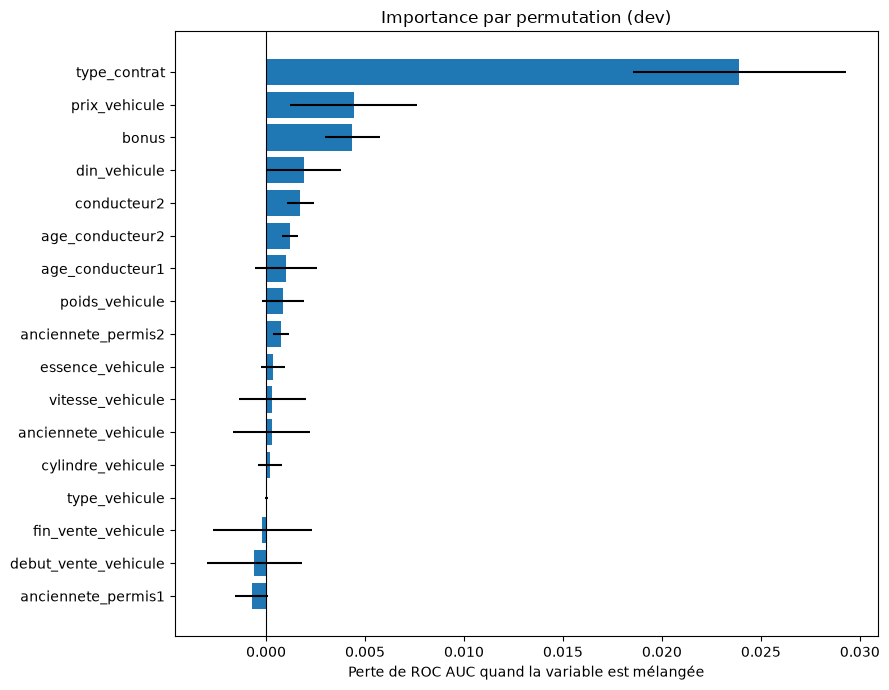

,variable,perte_AUC,ecart_type
13,type_contrat,0.0239,0.0054
8,prix_vehicule,0.0044,0.0032
0,bonus,0.0044,0.0014
2,din_vehicule,0.0019,0.0019
16,conducteur2,0.0017,0.0007
6,age_conducteur2,0.0012,0.0004
4,age_conducteur1,0.0010,0.0016
9,poids_vehicule,0.0009,0.0011
7,anciennete_permis2,0.0008,0.0004
15,essence_vehicule,0.0004,0.0006


In [35]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf, X_dev, y_dev, scoring="roc_auc",
                              n_repeats=10, random_state=42, n_jobs=-1)

imp_perm = pd.DataFrame({"variable": X_dev.columns,
                         "perte_AUC": perm.importances_mean,
                         "ecart_type": perm.importances_std}
                        ).sort_values("perte_AUC", ascending=True)

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(imp_perm["variable"], imp_perm["perte_AUC"], xerr=imp_perm["ecart_type"], color="tab:blue")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Perte de ROC AUC quand la variable est mélangée")
ax.set_title("Importance par permutation (dev)")
plt.tight_layout(); plt.show()

display(imp_perm.sort_values("perte_AUC", ascending=False).round(4))

- Interpretation 

type_contrat domine nettement : mélanger cette variable fait perdre environ 0,024 d’AUC, soit plus de cinq fois plus que n’importe quelle autre variable. Viennent ensuite prix_vehicule, bonus, din_vehicule et la présence d’un second conducteur, avec des effets modérés (0,002 à 0,0045) mais dont les barres d’erreur restent au-dessus de zéro. Les variables d’âge du véhicule (anciennete_vehicule, debut_vente, fin_vente) paraissent inutiles ou légèrement négatives, mais c’est un artefact : elles portent la même information, donc quand on en mélange une, les autres compensent. La permutation groupée a d’ailleurs montré que, prises ensemble, elles font partie des signaux dominants. Pour les variables dont la barre d’erreur traverse zéro (vitesse, cylindrée, carburant, type de véhicule, anciennete_permis1), l’importance n’est pas distinguable du bruit.

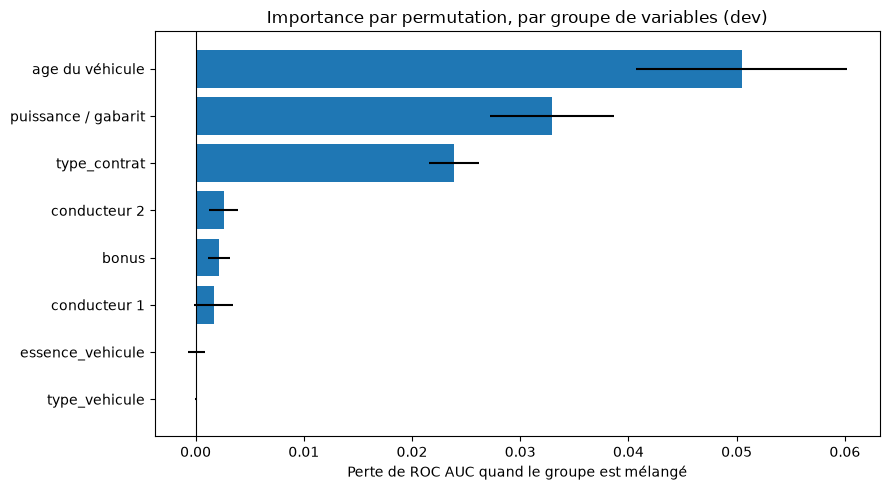

,groupe,perte_AUC,ecart_type
1,age du véhicule,0.0505,0.0097
2,puissance / gabarit,0.0329,0.0057
0,type_contrat,0.0239,0.0023
4,conducteur 2,0.0026,0.0013
3,bonus,0.0022,0.0010
5,conducteur 1,0.0017,0.0018
6,essence_vehicule,0.0001,0.0008
7,type_vehicule,0.0000,0.0001


In [36]:
from sklearn.metrics import roc_auc_score

groupes = {
    "type_contrat": ["type_contrat"],
    "age du véhicule": ["anciennete_vehicule", "debut_vente_vehicule", "fin_vente_vehicule"],
    "puissance / gabarit": ["prix_vehicule", "din_vehicule", "poids_vehicule",
                            "vitesse_vehicule", "cylindre_vehicule"],
    "bonus": ["bonus"],
    "conducteur 2": ["conducteur2", "age_conducteur2", "anciennete_permis2"],
    "conducteur 1": ["age_conducteur1", "anciennete_permis1"],
    "essence_vehicule": ["essence_vehicule"],
    "type_vehicule": ["type_vehicule"],
}

auc_ref = roc_auc_score(y_dev, rf.predict_proba(X_dev)[:, 1])
rng = np.random.default_rng(42)
res = []

for nom, cols in groupes.items():
    pertes = []
    for _ in range(10):
        Xp = X_dev.copy()
        idx = rng.permutation(len(Xp))
        Xp[cols] = Xp[cols].values[idx]       # même permutation pour tout le groupe
        pertes.append(auc_ref - roc_auc_score(y_dev, rf.predict_proba(Xp)[:, 1]))
    res.append({"groupe": nom, "perte_AUC": np.mean(pertes), "ecart_type": np.std(pertes)})

imp_g = pd.DataFrame(res).sort_values("perte_AUC")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(imp_g["groupe"], imp_g["perte_AUC"], xerr=imp_g["ecart_type"], color="tab:blue")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Perte de ROC AUC quand le groupe est mélangé")
ax.set_title("Importance par permutation, par groupe de variables (dev)")
plt.tight_layout(); plt.show()
display(imp_g.sort_values("perte_AUC", ascending=False).round(4))

- Interpretation 

En mélangeant ensemble les variables qui portent la même information, l’âge du véhicule devient le premier facteur de risque (perte d’AUC de 0,050), devant la puissance / gabarit (0,033) et le type de contrat (0,024). Cela corrige la lecture individuelle, où l’âge du véhicule semblait inutile parce que ses variables redondantes se compensaient entre elles. Les informations sur les conducteurs (second conducteur 0,0026, bonus 0,0022, conducteur principal 0,0017) ont un effet réel mais environ dix fois plus faible, et celui du conducteur principal reste incertain (écart-type aussi grand que l’effet). Le carburant et le type de véhicule n’apportent aucun signal propre (perte ≈ 0), ce qui a justifié leur retrait du modèle final. Le risque de sinistre est donc porté d’abord par les caractéristiques du véhicule et le niveau de garantie, bien plus que par le profil du conducteur.

In [37]:
def construire_preprocesseur(num, cat):
    def structurels(X):
        X = X.copy()
        if "age_conducteur2" in X.columns:
            sans_c2 = X["conducteur2"] == "No"
            X.loc[sans_c2, ["age_conducteur2", "anciennete_permis2"]] = 0
        return X

    colonnes = ColumnTransformer([
        ("num", SimpleImputer(strategy="median", add_indicator=True), num),
        ("cat", Pipeline([
            ("imputation", SimpleImputer(strategy="constant", fill_value="Inconnu")),
            ("encodage", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30,
                                       drop="if_binary", sparse_output=False)),
        ]), cat),
    ])
    return Pipeline([("structurels", FunctionTransformer(structurels, feature_names_out="one-to-one")),
                     ("colonnes", colonnes)])

def tester(num, cat, nom):
    modele = Pipeline([
        ("prep", construire_preprocesseur(num, cat)),
        ("modele", RandomForestClassifier(n_estimators=300, min_samples_leaf=200,
                                          max_features="sqrt", n_jobs=-1, random_state=42)),
    ])
    modele.fit(X_train[num + cat], y_train)
    r = evaluer(modele, X_dev[num + cat], y_dev, nom)
    r["nb_variables"] = len(num + cat)
    return r

cat_reduit = ["type_contrat", "conducteur2"]
num_sans_c1 = [c for c in num_rf if c not in ["age_conducteur1", "anciennete_permis1"]]

comparaison = pd.DataFrame([
    tester(num_rf, cat_rf, "Complet"),
    tester(num_rf, cat_reduit, "Sans essence ni type_vehicule"),
    tester(num_sans_c1, cat_reduit, "Sans essence, type_vehicule, conducteur 1"),
]).round(4)
display(comparaison)

,jeu,ROC_AUC,PR_AUC,Brier,proba_moy,nb_variables
0,Complet,0.6643,0.0977,0.0539,0.0586,17
1,Sans essence ni type_vehicule,0.6629,0.0976,0.0540,0.0586,15
2,"Sans essence, type_vehicule, conducteur 1",0.6611,0.0961,0.0540,0.0587,13


- Interpretation 

Sélection de variables par retrait successif (modèle de fréquence, dev)

Retirer le carburant et le type de véhicule (17 → 15 variables) ne coûte presque rien : ROC AUC de 0,6643 à 0,6629 (−0,0014), PR AUC et Brier inchangés. Ces deux variables n’apportaient donc pas d’information propre, ce que confirmait la permutation groupée. Retirer en plus les variables du conducteur principal (13 variables) fait perdre davantage (−0,0032 d’AUC et −0,0016 de PR AUC par rapport au modèle complet) : l’effet est faible, mais constant sur les deux métriques de classement. La calibration reste stable dans les trois cas (probabilité moyenne ≈ 5,86 % pour un taux réel de 5,83 %). Le modèle à 15 variables offre le meilleur compromis : plus simple que le modèle complet, sans perte de performance mesurable.

# Entrainement final 

In [38]:
num_final = num_rf
cat_final = ["type_contrat", "conducteur2"]
cols_final = num_final + cat_final

X_final = pd.concat([X_train, X_dev])[cols_final]
y_final = pd.concat([y_train, y_dev])

rf_final = Pipeline([
    ("prep", construire_preprocesseur(num_final, cat_final)),
    ("modele", RandomForestClassifier(n_estimators=300, min_samples_leaf=200,
                                      max_features="sqrt", n_jobs=-1, random_state=42)),
])
rf_final.fit(X_final, y_final)

naif_final = Pipeline([("prep", construire_preprocesseur(num_final, cat_final)),
                       ("modele", DummyClassifier(strategy="prior"))])
naif_final.fit(X_final, y_final)

res_test = pd.DataFrame([
    evaluer(naif_final, X_test[cols_final], y_test, "Naïf - test"),
    evaluer(rf_final, X_test[cols_final], y_test, "RF - test"),
]).round(4)
display(res_test)

,jeu,ROC_AUC,PR_AUC,Brier,proba_moy
0,Naïf - test,0.5000,0.0584,0.0550,0.0583
1,RF - test,0.6285,0.0852,0.0544,0.0588


In [39]:
p_test = rf_final.predict_proba(X_test[cols_final])[:, 1]
lift_t = pd.DataFrame({"proba": p_test, "reel": y_test.values})
lift_t["decile"] = pd.qcut(lift_t["proba"].rank(method="first"), 10, labels=range(1, 11))

tab_t = lift_t.groupby("decile", observed=True).agg(proba_moy=("proba", "mean"),
                                                    taux_reel=("reel", "mean"),
                                                    nb_sinistres=("reel", "sum"),
                                                    effectif=("reel", "size"))
tab_t["lift"] = tab_t["taux_reel"] / y_test.mean()
display(tab_t.round(3))

top30 = tab_t.loc[[8, 9, 10], "nb_sinistres"].sum() / tab_t["nb_sinistres"].sum()
print(f"Part des sinistres dans les 30 % les plus risqués : {top30:.1%}")

,proba_moy,taux_reel,nb_sinistres,effectif,lift
decile,,,,,
1,0.014,0.022,11,500,0.377
2,0.025,0.024,12,500,0.411
3,0.034,0.040,20,500,0.685
4,0.045,0.032,16,500,0.548
5,0.055,0.068,34,500,1.164
6,0.065,0.066,33,500,1.130
7,0.072,0.078,39,500,1.336
8,0.079,0.080,40,500,1.370
9,0.089,0.074,37,500,1.267


Part des sinistres dans les 30 % les plus risqués : 43.5%


- Interpretation 

Lift par décile du modèle de fréquence retenu (leaf=200, 15 variables)

Le taux de sinistres réel passe de 2,2 % dans le décile le moins risqué à 10,0 % dans le plus risqué, soit un rapport d’environ 4,5 : le modèle sépare clairement les bons et les mauvais risques (lift de 0,38 à 1,71). La progression est globalement régulière ; les petites inversions (décile 4 sous le 3, décile 9 sous le 8) s’expliquent par le faible nombre de sinistres par décile (11 à 50), qui rend chaque taux un peu bruité. Les probabilités prédites suivent de près les taux observés : le modèle est bien calibré, avec une légère sous-estimation des meilleurs risques (1,4 % prédit contre 2,2 %) et une légère surestimation des plus risqués (11,0 % contre 10,0 %). Les 30 % d’assurés jugés les plus risqués concentrent 43,5 % des sinistres, contre 30 % avec un tri au hasard. En tarification, cela justifie une prime environ 4 fois plus élevée pour le décile le plus risqué que pour le plus sûr.

In [40]:
import sys
import pickle
from pathlib import Path

RACINE = Path.cwd().parent if Path.cwd().name == "developement" else Path.cwd()
if str(RACINE / "inference_test") not in sys.path:
    sys.path.insert(0, str(RACINE / "inference_test"))

from preparation import construire_preprocesseur

rf_final = Pipeline([
    ("prep", construire_preprocesseur(num_final, cat_final)),
    ("modele", RandomForestClassifier(n_estimators=300, min_samples_leaf=200,
                                      max_features="sqrt", n_jobs=-1, random_state=42)),
])
rf_final.fit(X_final, y_final)

MODELE_DIR = RACINE / "models"
MODELE_DIR.mkdir(exist_ok=True)
with open(MODELE_DIR / "rf_proba_model.pkl", "wb") as f:
    pickle.dump(rf_final, f)
